# Contexto dado ao LLM (entrada) — `input_model_receives.png`

Mesmo gráfico de `graphic/input/grafico_entrada_input.ipynb`. Os números vêm da coluna *Input context* de `../data/tabela_de_codigos_artefatos.csv` (uma categoria de contexto por estudo).

In [1]:
import sys
sys.path.insert(0, "../scripts")   # graficos/scripts: dados_artefatos.py, paleta_grupos.py

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import dados_artefatos as da
from paleta_grupos import tons_grupo, CINZA_OUTROS, CINZA_INDEFINIDO

# família verde do grupo input: barras num tom médio-escuro; "Other" em cinza
cor_barra = tons_grupo("input", 5)[3]
cor_outros = CINZA_OUTROS

In [2]:
# rótulo de cada código no gráfico
rotulos = {
    "IX1": "Artifact under test\n(code, signature, docstring)",
    "IX2": "Structured\nrepresentation of UI",
    "IX3": "Previous output /\nexecution feedback",
    "IX4": "Requirements /\ndocumentation (NL)",
    "IX5": "Formal API /\nprotocol specification",
    "IX6": "Bug report / issue",
    "IX7": "Other",
}
contagem = da.contagem("Input context")
ordem = sorted([c for c in rotulos if c != "IX7"], key=lambda c: -contagem[c]) + ["IX7"]   # decrescente, "Other" no fim
dados = [{"tipo": rotulos[c], "valor": int(contagem[c]), "cor": cor_outros if c == "IX7" else cor_barra} for c in ordem]

x_pos = range(len(dados))
total = sum(d["valor"] for d in dados)
print(contagem.to_dict(), "total =", total)
assert total == len(da.estudos("Input context"))

{'IX1': 54, 'IX2': 29, 'IX3': 16, 'IX4': 37, 'IX5': 10, 'IX6': 5, 'IX7': 21} total = 172


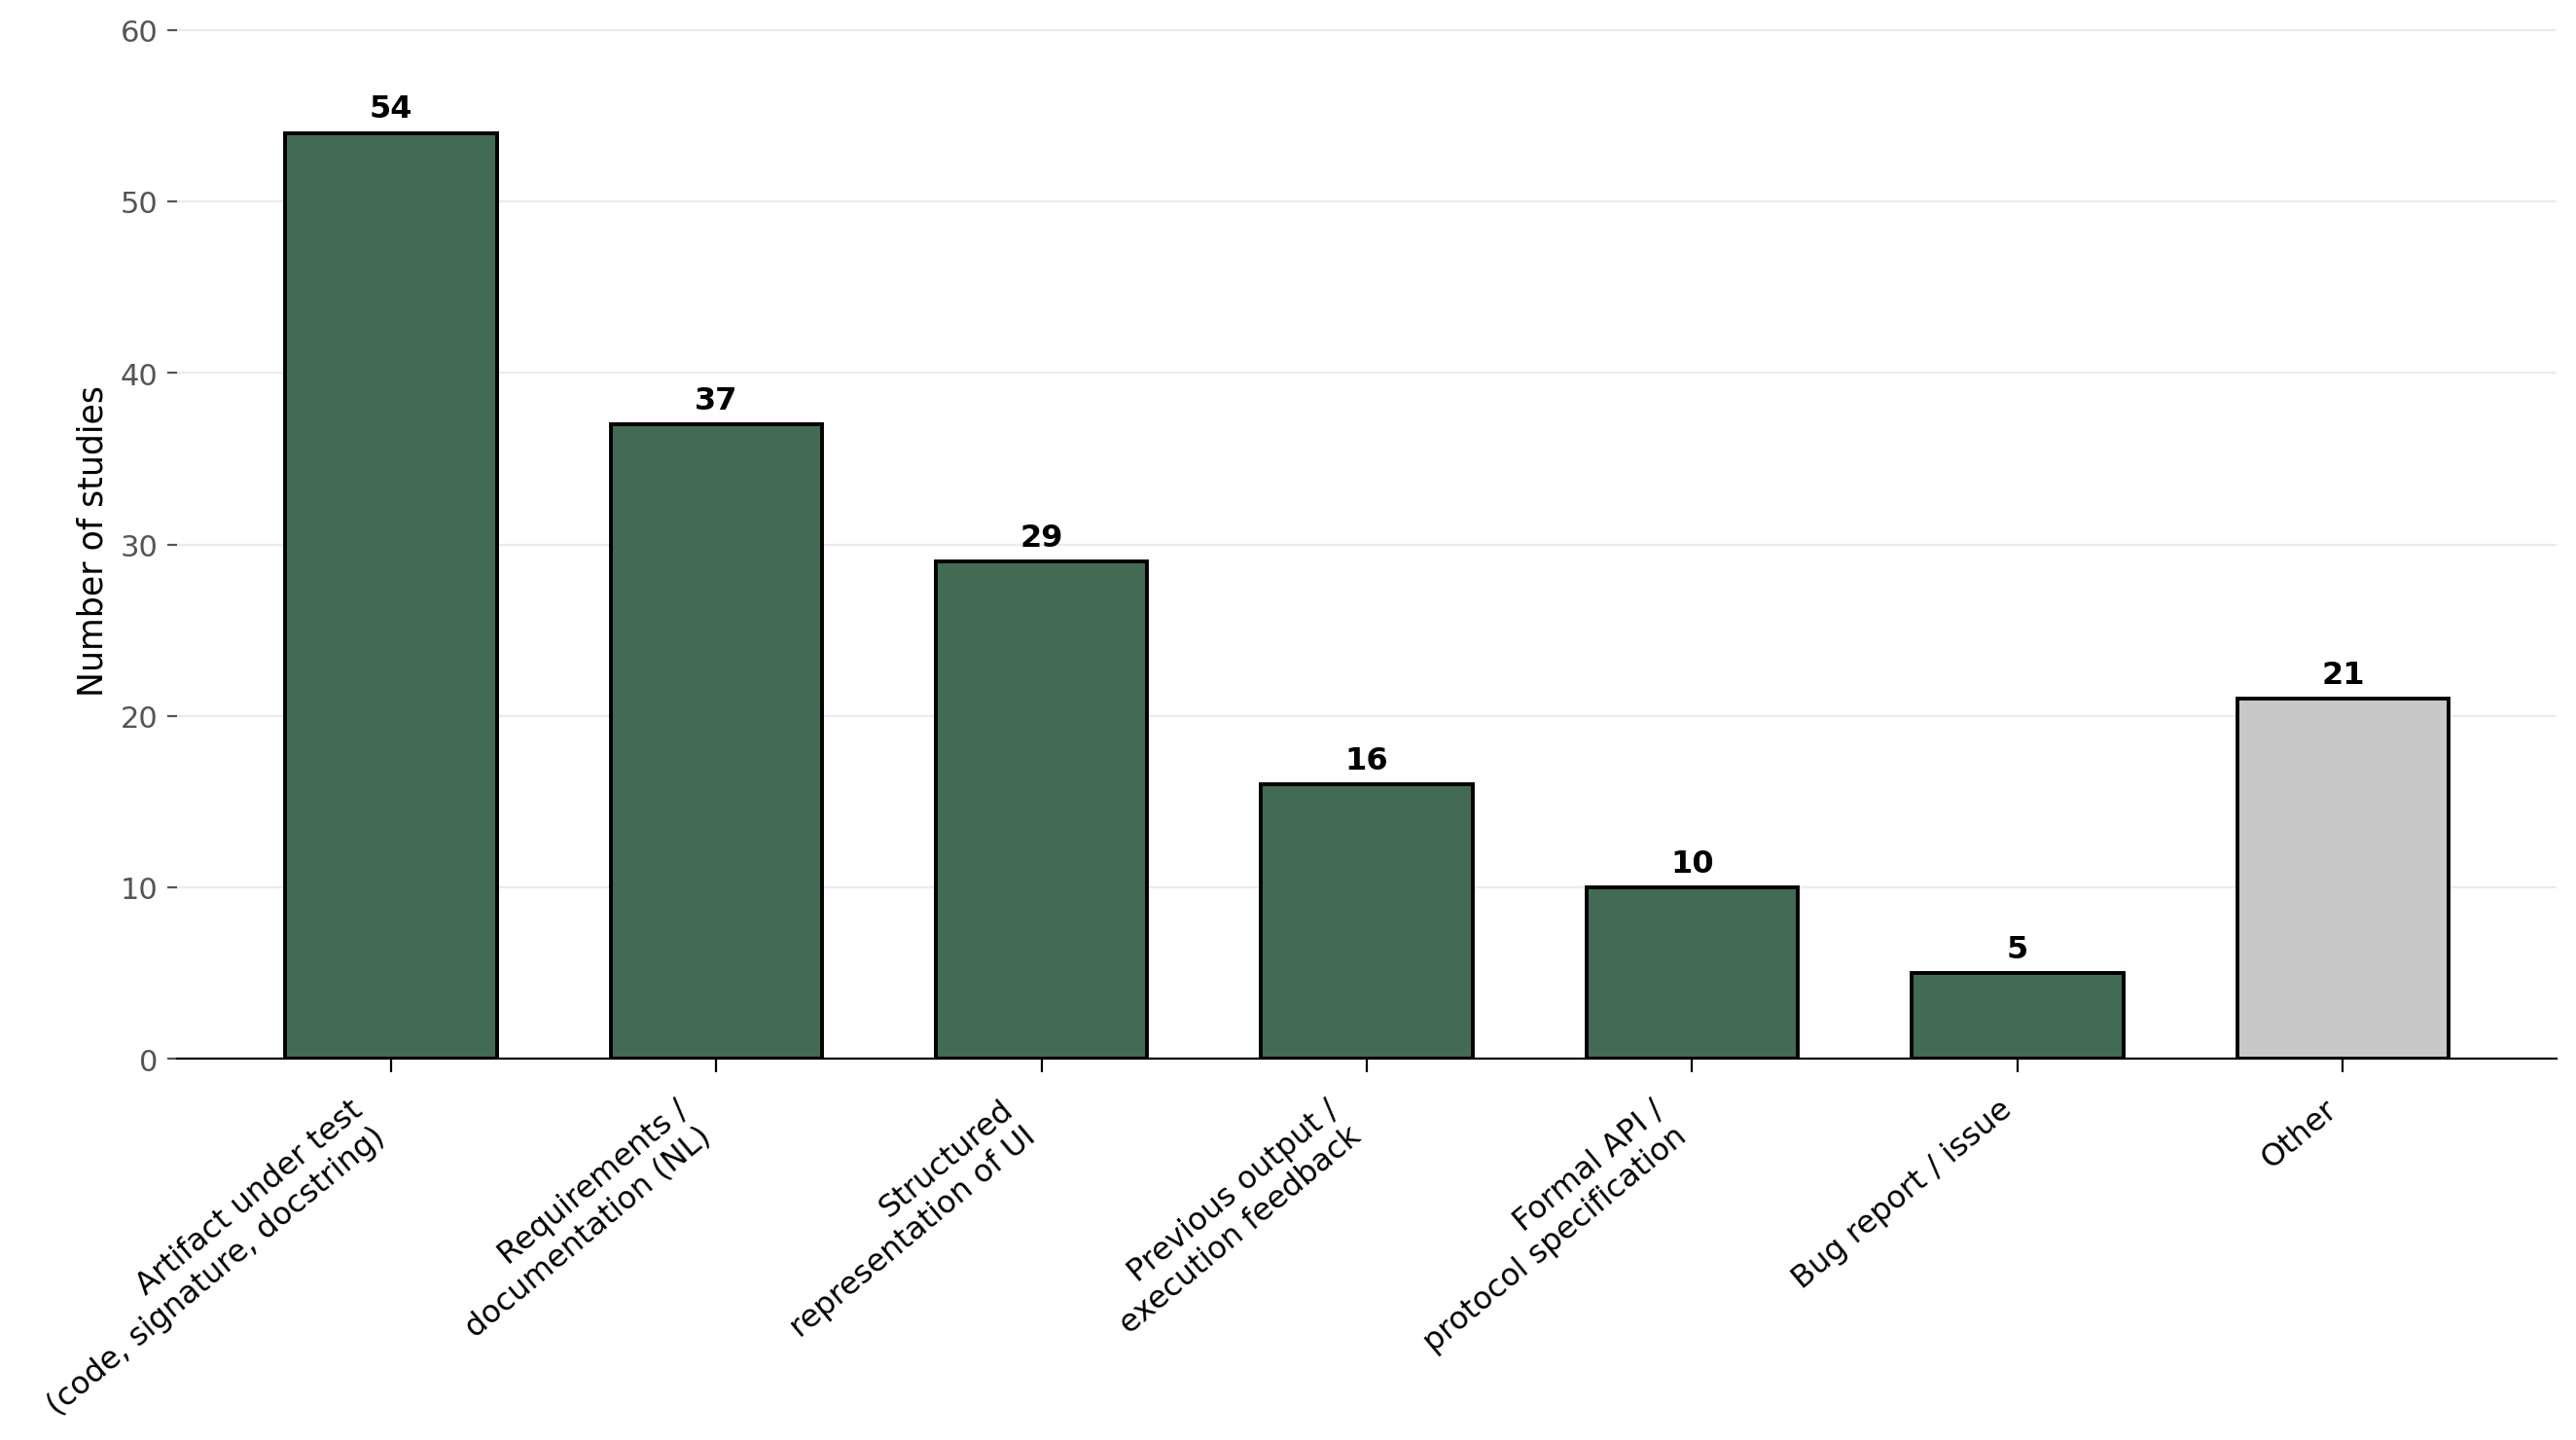

In [3]:
fig, ax = plt.subplots(figsize=(13.5, 7.5), dpi=200)

for x, d in zip(x_pos, dados):
    ax.bar(x, d["valor"], color=d["cor"], width=0.65, edgecolor="black", linewidth=1.4, zorder=3)
    ax.text(
        x, d["valor"] + 0.5, str(d["valor"]),
        ha="center", va="bottom", fontsize=11.5, fontweight="bold", color="black",
    )

ax.set_xticks(list(x_pos))
ax.set_xticklabels([d["tipo"] for d in dados], rotation=40, ha="right", fontsize=11.5)

ax.set_ylim(0, max(d["valor"] for d in dados) * 1.12)
ax.set_ylabel("Number of studies", fontsize=12.5)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color("black")
ax.tick_params(axis="x", length=5, pad=8, color="black")
ax.tick_params(axis="y", colors="#555555", labelsize=11)
ax.yaxis.grid(True, color="#e8ecf3", zorder=0)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("input_model_receives.png", bbox_inches="tight", dpi=200)
plt.savefig("input_model_receives.pdf", bbox_inches="tight")
plt.show()